✓ Toutes les tables chargées

  TABLE : ORDERS  — 99441 lignes × 8 colonnes
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Aperçu :
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27          2018-0

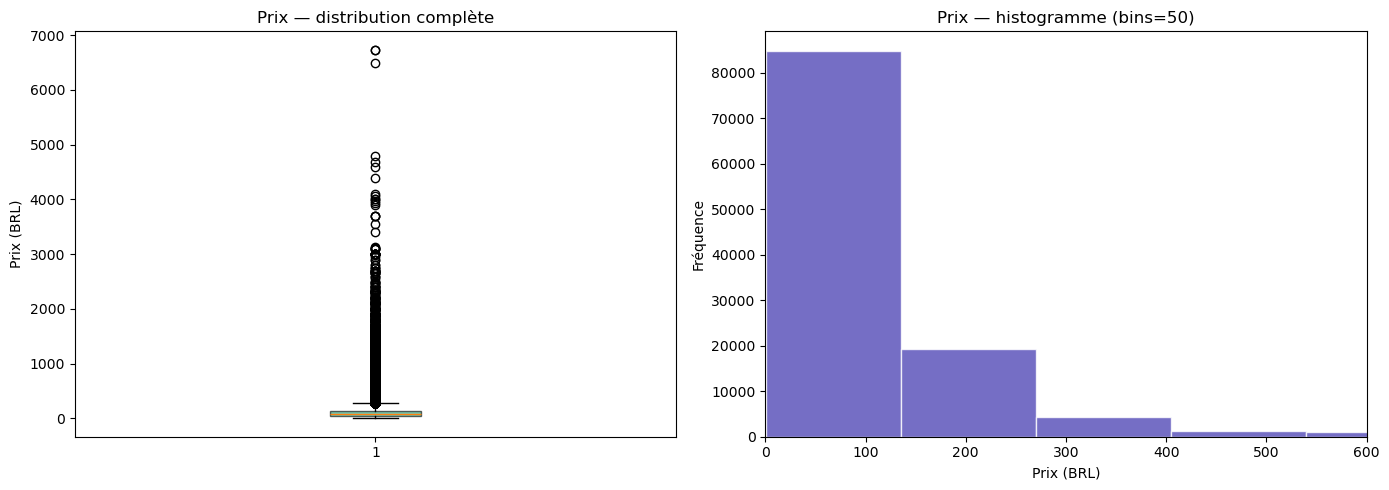

=== MÉTHODE IQR — PRIX ===
  Q1            : 39.90 BRL
  Médiane (Q2)  : 74.99 BRL
  Q3            : 134.90 BRL
  IQR           : 95.00 BRL
  Borne basse   : -102.60 BRL
  Borne haute   : 277.40 BRL

  Outliers détectés : 8427 (7.48%)
  Données normales  : 104223 (92.52%)

=== INSPECTION DES OUTLIERS PRIX ===
count    8427.000000
mean      574.291188
std       431.196659
min       277.450000
25%       329.000000
50%       409.990000
75%       649.000000
max      6735.000000
Name: price, dtype: float64

Top 10 prix les plus élevés :
                              product_id    price  freight_value
3556    489ae2aa008f021502940f251d4cce7f  6735.00         194.31
112233  69c590f7ffc7bf8db97190b6cb6ed62e  6729.00         193.21
107841  1bdf5e6731585cf01aa8169c7028d6ad  6499.00         227.66
74336   a6492cc69376c469ab6f61d8f44de961  4799.00         151.34
11249   c3ed642d592594bb648ff4a04cee2747  4690.00          74.34
62086   259037a6a41845e455183f89c5035f18  4590.00          91.78
29193  

In [ ]:
# En haut de chaque notebook — import unique
import sys
sys.path.append('..')
from src.utils import *

# Audit
audit_table('orders', orders)
rapport_nulls({'orders': orders, 'items': items})

# Nettoyage
orders = convertir_dates(orders, ['order_purchase_timestamp',
                                   'order_approved_at',
                                   'order_delivered_customer_date'])

products = imputer_mediane(products, ['product_weight_g',
                                       'product_length_cm'])

# Outliers
items, b_low, b_high = detecter_outliers_iqr(items, 'price')

# Visualisation
plot_boxplot_hist(items, 'price',
                  save_path='../reports/figures/prix.png',
                  xlim=(0, 500))

# Export
exporter_tables({'orders': orders, 'items': items}, '../data/processed')